***CLASSIFICAÇÃO FEW-SHORT DE DOENÇAS DE PLANTAS VIA FUSÃO DE CARACTERÍSITICAS GLOBAL-LOCAL***

---



Este trabalho implementa uma abordagem de Aprendizado com Poucos Exemplos (Few-Shot Learning – FSL) baseada no método de Fusão de Características Global-Local, inspirado no artigo Few-Shot Image Classification Algorithm Based on Global–Local Feature Fusion (Zhang et al., 2025). O objetivo é realizar a classificação de espécies de plantas utilizando poucas imagens de treinamento para cada classe. Diferentemente dos métodos tradicionais de Deep Learning, que normalmente necessitam de milhares de imagens rotuladas, o Few-Shot Learning busca aprender novas categorias a partir de apenas alguns exemplos. Neste projeto foi adotado um cenário 5-way 5-shot, no qual o modelo aprende a distinguir cinco espécies de plantas utilizando apenas cinco imagens de suporte para cada uma delas.
A principal característica do método é combinar informações obtidas em duas escalas diferentes da imagem. O ramo global captura características gerais, como formato, estrutura e distribuição espacial da planta, enquanto o ramo local analisa pequenos recortes da imagem, permitindo identificar detalhes discriminativos como textura das folhas, nervuras, bordas e outras particularidades visuais. Após a extração dessas características, é aplicado um mecanismo de Self-Attention, responsável por atribuir diferentes níveis de importância às regiões locais extraídas. Dessa forma, o modelo aprende automaticamente quais partes da imagem são mais relevantes para diferenciar cada espécie, reduzindo a influência de regiões pouco informativas.

Outra característica importante dessa abordagem é a utilização de um backbone pré-treinado (ResNet18), empregado apenas como extrator de características. Em vez de realizar o ajuste fino de todos os pesos da rede — processo computacionalmente caro e sujeito ao overfitting quando existem poucos dados — o método mantém o backbone congelado e realiza a classificação por meio de Protótipos de Classe. Cada classe é representada pelo vetor médio de características obtido a partir das imagens do conjunto de suporte (Support Set). Durante a fase de teste, cada imagem do conjunto de consulta (Query Set) é projetada para o mesmo espaço de características e classificada de acordo com a menor Distância Euclidiana entre seu vetor e os protótipos das classes conhecidas. Essa estratégia reduz significativamente o custo computacional e melhora a capacidade de generalização para novas espécies com poucas amostras disponíveis.

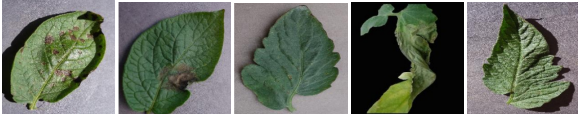

### CÉLULA 1 – Criação da Estrutura do Experimento

---



Cria automaticamente a estrutura de diretórios utilizada durante o experimento, organizando os conjuntos de suporte (Support Set) e consulta (Query Set). No Few-Shot Learning, os dados são divididos em dois conjuntos fundamentais:


*   Support Set (S): pequeno conjunto contendo os exemplos que representam cada classe.
*   Query Set (Q): conjunto de imagens utilizado para avaliar a capacidade de generalização do modelo.



In [1]:
import os

# Diretórios utilizados no experimento
base_dir = "projeto_few_shot"
meta_test_dir = os.path.join(base_dir, "meta_test")

support_dir = os.path.join(meta_test_dir, "support")
query_dir = os.path.join(meta_test_dir, "query")

# Criação dos diretórios
folders_to_create = [
    support_dir,
    query_dir
]

for folder in folders_to_create:
    os.makedirs(folder, exist_ok=True)
    print(f"Diretório criado: {folder}")

Diretório criado: projeto_few_shot/meta_test/support
Diretório criado: projeto_few_shot/meta_test/query


### CÉLULA 2 — Preparação do Dataset PlantVillage

Esta etapa realiza o download e a extração do conjunto de dados PlantVillage, utilizado para a classificação de doenças em folhas de plantas.

O dataset contém imagens organizadas por categorias, incluindo diferentes espécies e condições de saúde das plantas.

As imagens serão utilizadas posteriormente na construção dos conjuntos de suporte (*Support Set*) e consulta (*Query Set*) do experimento Few-Shot Learning.

In [2]:

import zipfile
import urllib.request
import os

url = "https://github.com/spMohanty/PlantVillage-Dataset/archive/refs/heads/master.zip"
zip_path = "plantvillage.zip"
extract_path = "plantvillage_raw"

if not os.path.exists(extract_path):
    print("Preparando dataset PlantVillage...")

    if not os.path.exists(zip_path):
        print("Baixando dataset...")
        urllib.request.urlretrieve(url, zip_path)
    else:
        print("Arquivo ZIP já encontrado. Evitando novo download.")

    print("Descompactando arquivos...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset descompactado com sucesso!")

else:
    print("Dataset PlantVillage já está disponível. Download dispensado.")


Dataset PlantVillage já está disponível. Download dispensado.


### CÉLULA 3 — Construção do Cenário Few-Shot

Nesta etapa, são selecionadas cinco classes de doenças do dataset PlantVillage. As imagens de cada classe são embaralhadas aleatoriamente e distribuídas em dois conjuntos: suporte (*Support Set*) e consulta (*Query Set*).

O experimento utiliza a configuração **5-way 5-shot**, com os seguintes parâmetros:

- **5-way:** cinco classes participantes do experimento;
- **5-shot:** cinco imagens de suporte por classe, totalizando 25 imagens;
- **Query Set:** 100 imagens por classe destinadas à avaliação, totalizando 500 imagens.

A utilização de uma semente aleatória fixa (`random.seed(42)`) permite reproduzir a mesma seleção de imagens em execuções posteriores.

In [3]:
import glob
import random
import shutil
import os

raw_data_path = "plantvillage_raw/PlantVillage-Dataset-master/raw/color/"

# 5 Doenças para testar a generalização
classes_escolhidas = [
    "Tomato___Bacterial_spot",
    "Tomato___Late_blight",
    "Tomato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight"
]

K_SHOT = 5       # 5 fotos de exemplo no suporte
NUM_QUERY = 100  #100 fotos de teste por doença

# Limpa execuções antigas para não misturar dados de 3 com 5 classes
if os.path.exists(support_dir): shutil.rmtree(support_dir)
if os.path.exists(query_dir): shutil.rmtree(query_dir)

for classe in classes_escolhidas:
    os.makedirs(os.path.join(support_dir, classe), exist_ok=True)
    os.makedirs(os.path.join(query_dir, classe), exist_ok=True)

    imagens = glob.glob(os.path.join(raw_data_path, classe, "*.JPG")) + glob.glob(os.path.join(raw_data_path, classe, "*.jpg"))
    random.seed(42) # Garante repetibilidade do sorteio
    random.shuffle(imagens)

    for i in range(K_SHOT):
        shutil.copy(imagens[i], os.path.join(support_dir, classe, os.path.basename(imagens[i])))

    for i in range(K_SHOT, K_SHOT + NUM_QUERY):
        shutil.copy(imagens[i], os.path.join(query_dir, classe, os.path.basename(imagens[i])))

print(f"Cenário Few-Shot montado: {len(classes_escolhidas)} classes (doenças).")
print(f"Total de imagens que serão testadas: {len(classes_escolhidas) * NUM_QUERY}")

Cenário Few-Shot montado: 5 classes (doenças).
Total de imagens que serão testadas: 500


### CÉLULA 4 - Mecanismo de Self-Attention

As características extraídas dos cinco recortes locais são processadas por uma camada de Self-Attention, utilizando as próprias características como consultas (Query), chaves (Key) e valores (Value).

As matrizes de projeção da atenção são inicializadas com matrizes identidade e mantidas fixas durante o experimento, sem atualização por treinamento. Dessa forma, o mecanismo realiza a combinação das informações entre os diferentes recortes, sem aprender parâmetros específicos a partir dos dados.

Após o processamento, as características locais são agregadas por meio da média e normalizadas, sendo posteriormente concatenadas às características globais extraídas pela ResNet18.

In [4]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import random
import numpy as np

# Configuração para reprodutibilidade
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

class GlobalLocalFewShotModel(nn.Module):
    def __init__(self, embed_dim=512):
        super(GlobalLocalFewShotModel, self).__init__()

        # Backbone ResNet18 pré-treinado
        resnet = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )
        self.backbone = nn.Sequential(
            *list(resnet.children())[:-1]
        )

        # Congela os parâmetros da ResNet18
        for param in self.backbone.parameters():
            param.requires_grad = False

        # Cinco recortes locais determinísticos
        self.local_crops = transforms.FiveCrop(size=84)

        # Mecanismo de Self-Attention
        self.self_attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=4,
            batch_first=True
        )

        # Inicialização fixa das projeções de atenção
        with torch.no_grad():
            I = torch.eye(embed_dim)
            self.self_attention.in_proj_weight.copy_(
                torch.cat([I, I, I], dim=0)
            )
            self.self_attention.in_proj_bias.zero_()
            self.self_attention.out_proj.weight.copy_(I)
            self.self_attention.out_proj.bias.zero_()

    def forward(self, x):

        batch_size = x.size(0)

        # Características globais
        with torch.no_grad():
            R_g = self.backbone(x)

        R_g = F.normalize(
            R_g.view(batch_size, -1),
            p=2,
            dim=-1
        )

        # Extração dos cinco recortes locais
        crops = self.local_crops(x)
        crops = torch.stack(crops, dim=1)

        crops = crops.reshape(
            batch_size * 5,
            x.size(1),
            84,
            84
        )

        with torch.no_grad():
            local_features = self.backbone(crops)

        local_features = local_features.view(
            batch_size, 5, -1
        )

        local_features = F.normalize(
            local_features,
            p=2,
            dim=-1
        )

        # Self-Attention sobre as características locais
        attn_output, _ = self.self_attention(
            local_features,
            local_features,
            local_features
        )

        R_w = F.normalize(
            torch.mean(attn_output, dim=1),
            p=2,
            dim=-1
        )

        # Fusão Global-Local
        return F.normalize(
            torch.cat((R_g, R_w), dim=-1),
            p=2,
            dim=-1
        )

def compute_prototype_and_classify(support_features, support_labels, query_feature):
    unique_classes = torch.unique(support_labels)
    prototypes = {}
    for c in unique_classes:
        class_mask = (support_labels == c)
        prototypes[c.item()] = torch.mean(support_features[class_mask], dim=0)

    best_class, min_distance = None, float('inf')
    for c, proto in prototypes.items():
        dist = torch.dist(query_feature, proto, p=2)
        if dist < min_distance:
            min_distance = dist
            best_class = c
    return best_class

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GlobalLocalFewShotModel().to(device)
model.eval()
print("Modelo criado com sucesso!")

Modelo criado com sucesso!


### CÉLULA 5 – Implementação do Modelo Global-Local

---



Implementa a arquitetura de classificação composta por:


*   Backbone ResNet18 pré-treinado;
*   Extração de características globais;
*   Extração de características locais por meio de múltiplos recortes;
*   Mecanismo de Self-Attention;
*   Classificação utilizando Protótipos de Classe e Distância Euclidiana.

Inicialmente, a ResNet18 extrai características globais da imagem completa. Em seguida, diversos recortes locais são processados individualmente e refinados pelo mecanismo de Self-Attention. As características globais e locais são então combinadas para formar uma representação mais discriminativa da imagem. Por fim, é calculado o protótipo de cada classe como a média das características das imagens do conjunto de suporte. A classificação é realizada atribuindo cada imagem ao protótipo cuja distância euclidiana seja mínima.




VISUALIZADOR DAS IMAGENS

IMAGENS DO CONJUNTO DE CONSULTA (QUERY) QUE SERÃO ANALISADAS PELO MODELO:
--------------------------------------------------------------------------------


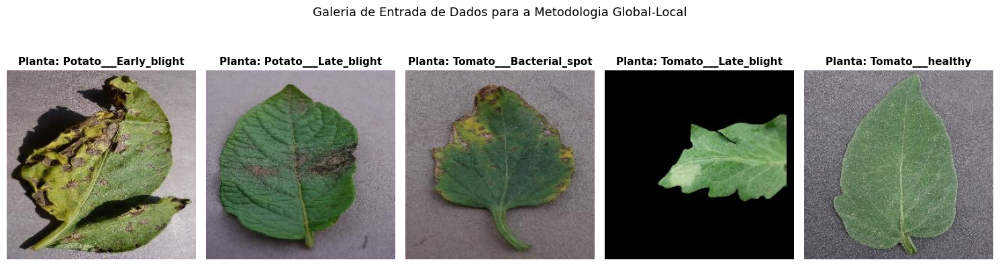

In [5]:
import matplotlib.pyplot as plt
import glob
from PIL import Image
import os

print("IMAGENS DO CONJUNTO DE CONSULTA (QUERY) QUE SERÃO ANALISADAS PELO MODELO:")
print("-" * 80)

pastas_plantas = sorted(glob.glob(os.path.join(query_dir, "*")))
plt.figure(figsize=(15, 4))

for idx, pasta in enumerate(pastas_plantas):
    nome_planta = os.path.basename(pasta)


    all_images_in_folder = glob.glob(os.path.join(pasta, "*.jpg")) + glob.glob(os.path.join(pasta, "*.JPG"))

    if all_images_in_folder: # Verifica se a lista não está vazia
        primeira_img = all_images_in_folder[0]
    else:
        print(f"Aviso: Nenhuma imagem .jpg ou .JPG encontrada na pasta: {pasta}. Pulando esta pasta.")
        continue

    img = Image.open(primeira_img)

    plt.subplot(1, 5, idx + 1)
    plt.imshow(img)
    plt.title(f"Planta: {nome_planta}", fontsize=11, weight='bold')
    plt.axis('off')

plt.suptitle("Galeria de Entrada de Dados para a Metodologia Global-Local", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

### CÉLULA 6 – Avaliação do Modelo

---
Executa a classificação das imagens do conjunto de consulta e calcula as principais métricas de desempenho, incluindo:

*   Precisão (Precision);
*   Revocação (Recall);
*   F1-Score;
*   Acurácia;
*   Matriz de Confusão







TESTE DE GENERALIZAÇÃO
Total de Folhas Avaliadas:     500
Diagnósticos CORRETOS (Acertos): 417 ✅
Diagnósticos INCORRETOS (Erros): 83 ❌

                       precision    recall  f1-score   support

  Potato Early_blight       0.93      0.98      0.96       100
   Potato Late_blight       0.94      0.84      0.89       100
Tomato Bacterial_spot       0.62      0.96      0.75       100
   Tomato Late_blight       0.85      0.62      0.72       100
       Tomato healthy       0.99      0.77      0.87       100

             accuracy                           0.83       500
            macro avg       0.87      0.83      0.84       500
         weighted avg       0.87      0.83      0.84       500

                       precision    recall  f1-score   support

  Potato Early_blight       0.93      0.98      0.96       100
   Potato Late_blight       0.94      0.84      0.89       100
Tomato Bacterial_spot       0.62      0.96      0.75       100
   Tomato Late_blight       0.85      0.

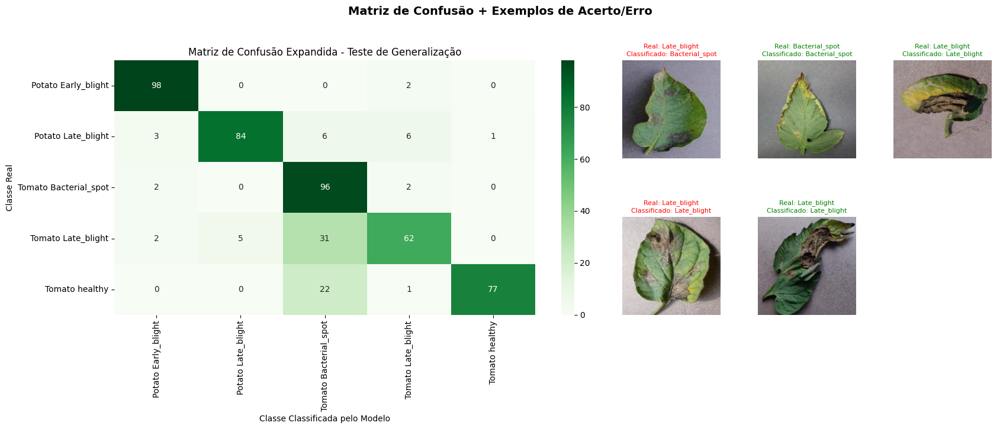

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

support_dataset = ImageFolder("projeto_few_shot/meta_test/support", transform=eval_transform)
query_dataset = ImageFolder("projeto_few_shot/meta_test/query", transform=eval_transform)

support_loader = DataLoader(support_dataset, batch_size=len(support_dataset), shuffle=False)
query_loader = DataLoader(query_dataset, batch_size=1, shuffle=False)

for images, labels in support_loader:
    images, labels = images.to(device), labels.to(device)
    with torch.no_grad():
        support_features = model(images)
    support_labels = labels

y_true = []
y_pred = []

for query_img, query_label in query_loader:
    query_img = query_img.to(device)
    with torch.no_grad():
        query_feature = model(query_img).squeeze(0)

    classe_predita = compute_prototype_and_classify(support_features, support_labels, query_feature)
    y_true.append(query_label.item())
    y_pred.append(classe_predita)

#  CÁLCULO DE QUANTIDADE ABSOLUTA
y_true_np = np.array(y_true)
y_pred_np = np.array(y_pred)
total_acertos = np.sum(y_true_np == y_pred_np)
total_erros = len(y_true) - total_acertos

print("\n=======================================================")
print("TESTE DE GENERALIZAÇÃO")
print("=======================================================")
print(f"Total de Folhas Avaliadas:     {len(y_true)}")
print(f"Diagnósticos CORRETOS (Acertos): {total_acertos} ✅")
print(f"Diagnósticos INCORRETOS (Erros): {total_erros} ❌")
print("=======================================================\n")

class_names_clean = [c.replace("___", " ").replace("__", " ") for c in query_dataset.classes]
print(classification_report(y_true, y_pred, target_names=class_names_clean))

import random

cm = confusion_matrix(y_true, y_pred)

# --- Seleciona até 5 exemplos (mistura de acertos e erros) para ilustrar ---
exemplos_corretos = [i for i in range(len(y_true)) if y_true[i] == y_pred[i]]
exemplos_errados  = [i for i in range(len(y_true)) if y_true[i] != y_pred[i]]

random.seed(42)
random.shuffle(exemplos_corretos)
random.shuffle(exemplos_errados)

n_errados = min(2, len(exemplos_errados))
n_corretos = min(5 - n_errados, len(exemplos_corretos))
indices_exemplo = exemplos_corretos[:n_corretos] + exemplos_errados[:n_errados]
random.shuffle(indices_exemplo)

# --- Figura combinada: matriz (esquerda) + exemplos (direita, 3 em cima / 3 em baixo) ---
fig = plt.figure(figsize=(17, 7))
gs = fig.add_gridspec(1, 2, width_ratios=[1.4, 1])

ax_cm = fig.add_subplot(gs[0, 0])
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names_clean, yticklabels=class_names_clean, ax=ax_cm)
ax_cm.set_title('Matriz de Confusão Expandida - Teste de Generalização')
ax_cm.set_ylabel('Classe Real')
ax_cm.set_xlabel('Classe Classificada pelo Modelo')

gs_imgs = gs[0, 1].subgridspec(2, 3, wspace=0.3, hspace=0.6)
for slot in range(6):
    row, col = divmod(slot, 3)
    ax = fig.add_subplot(gs_imgs[row, col])
    ax.axis('off')
    if slot < len(indices_exemplo):
        idx = indices_exemplo[slot]
        img_path, classe_id = query_dataset.samples[idx]
        pred = y_pred[idx]
        nome_real = query_dataset.classes[classe_id].split("___")[-1]
        nome_predito = query_dataset.classes[pred].split("___")[-1]
        cor = 'green' if pred == classe_id else 'red'
        ax.imshow(Image.open(img_path))
        ax.set_title(f"Real: {nome_real}\nClassificado: {nome_predito}", fontsize=8, color=cor)

fig.suptitle("Matriz de Confusão + Exemplos de Acerto/Erro", fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()

### CÉLULA 7 – Visualização dos Resultados

---
Seleciona uma imagem representativa de cada classe do conjunto de teste e apresenta:


*   imagem original;
*   classe verdadeira;
*   classe prevista pelo modelo.





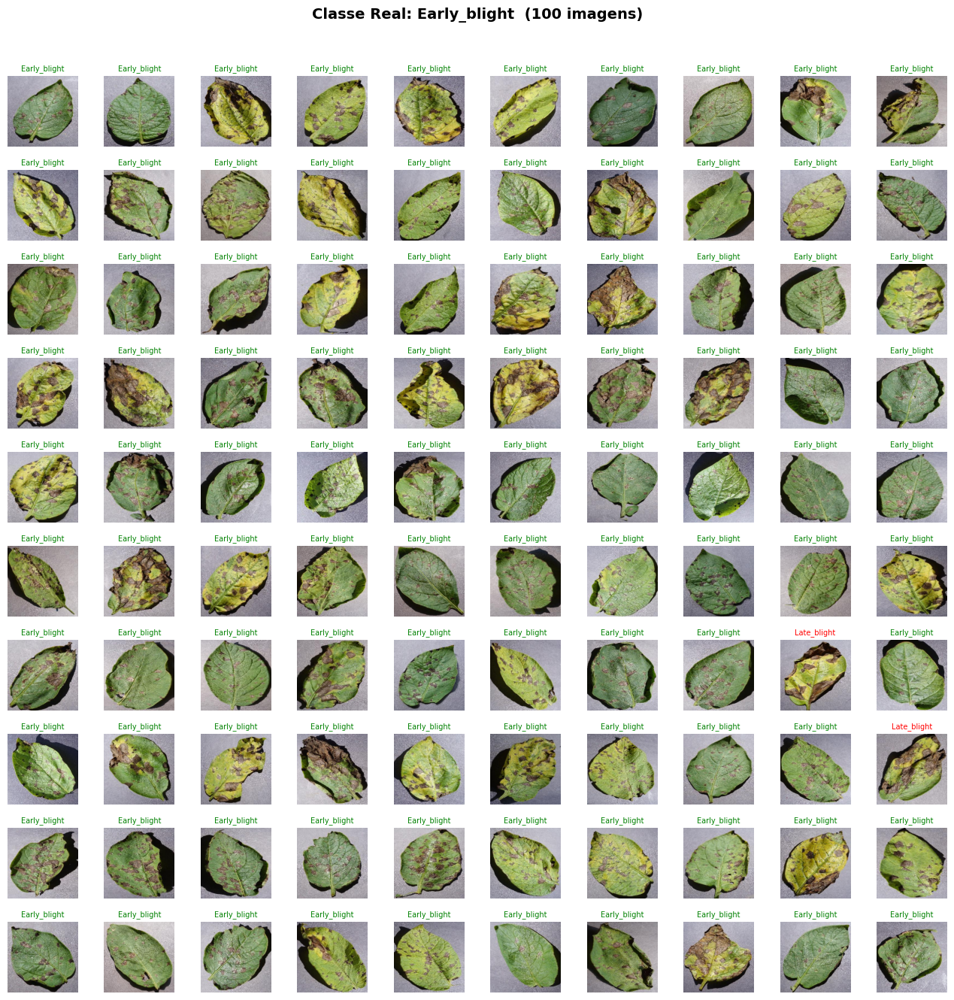

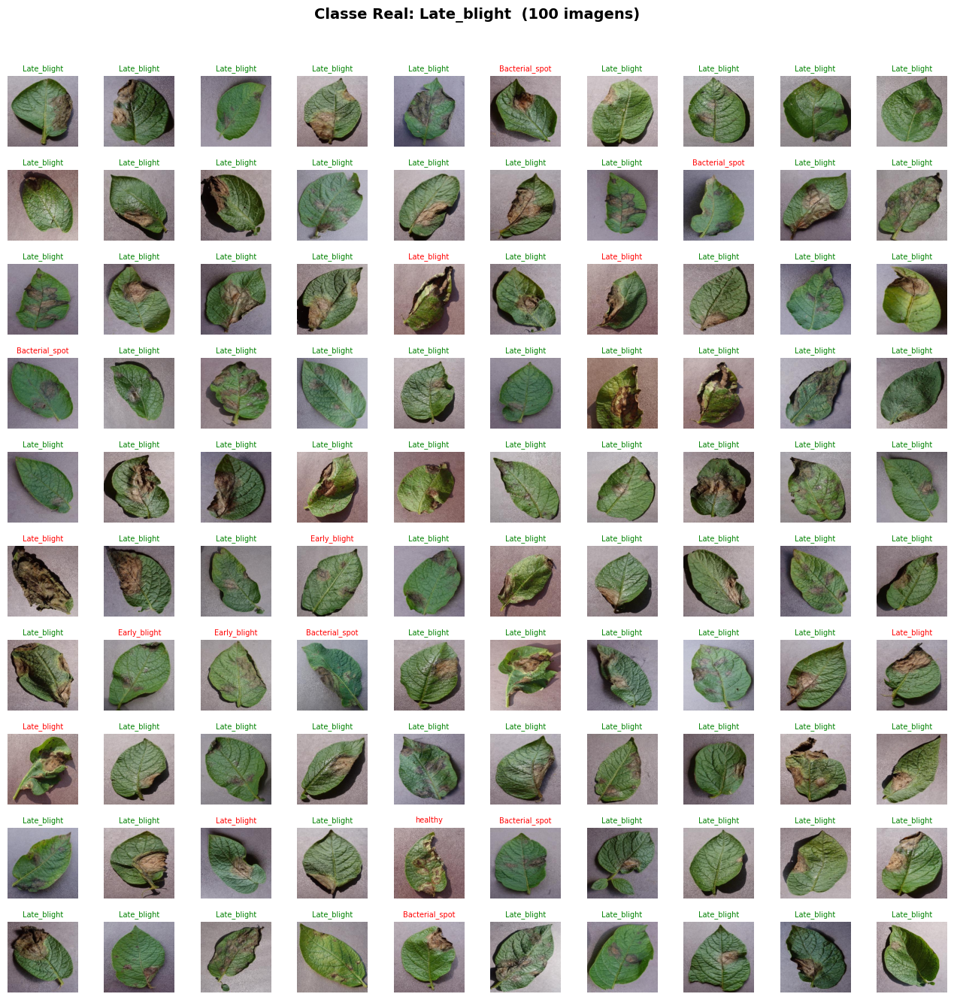

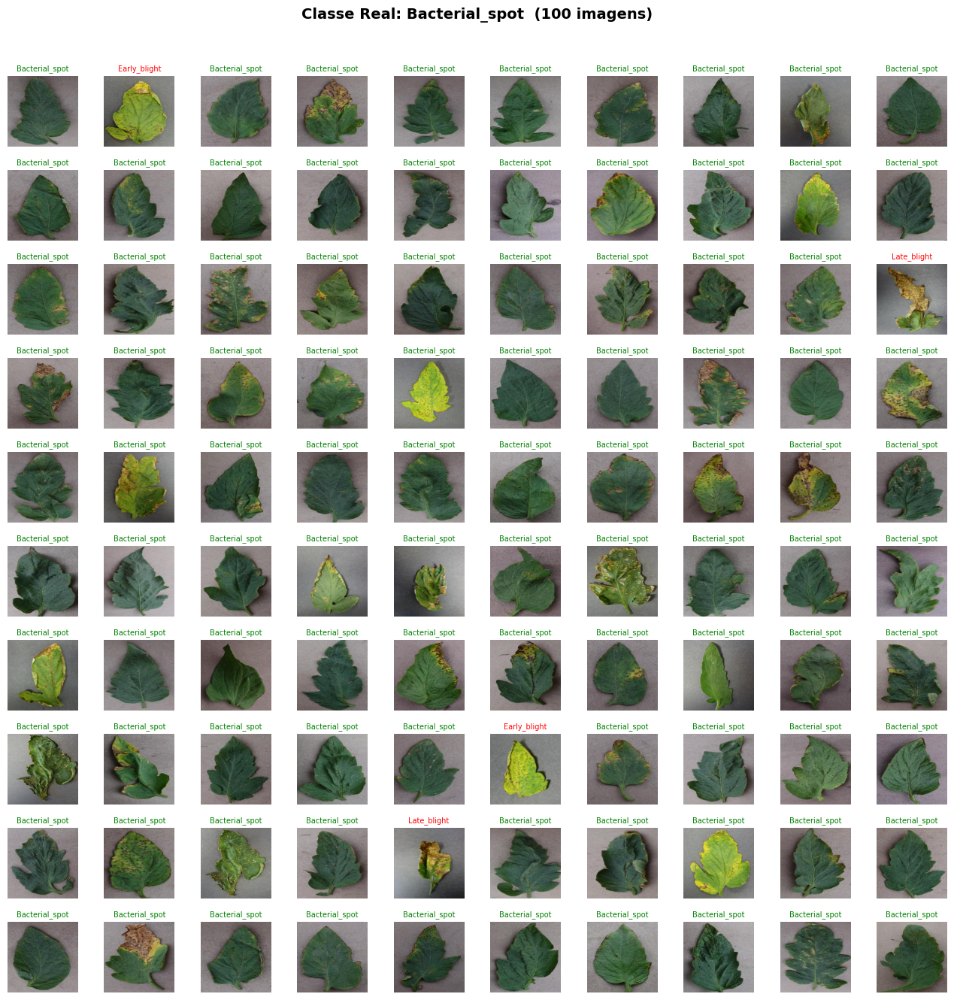

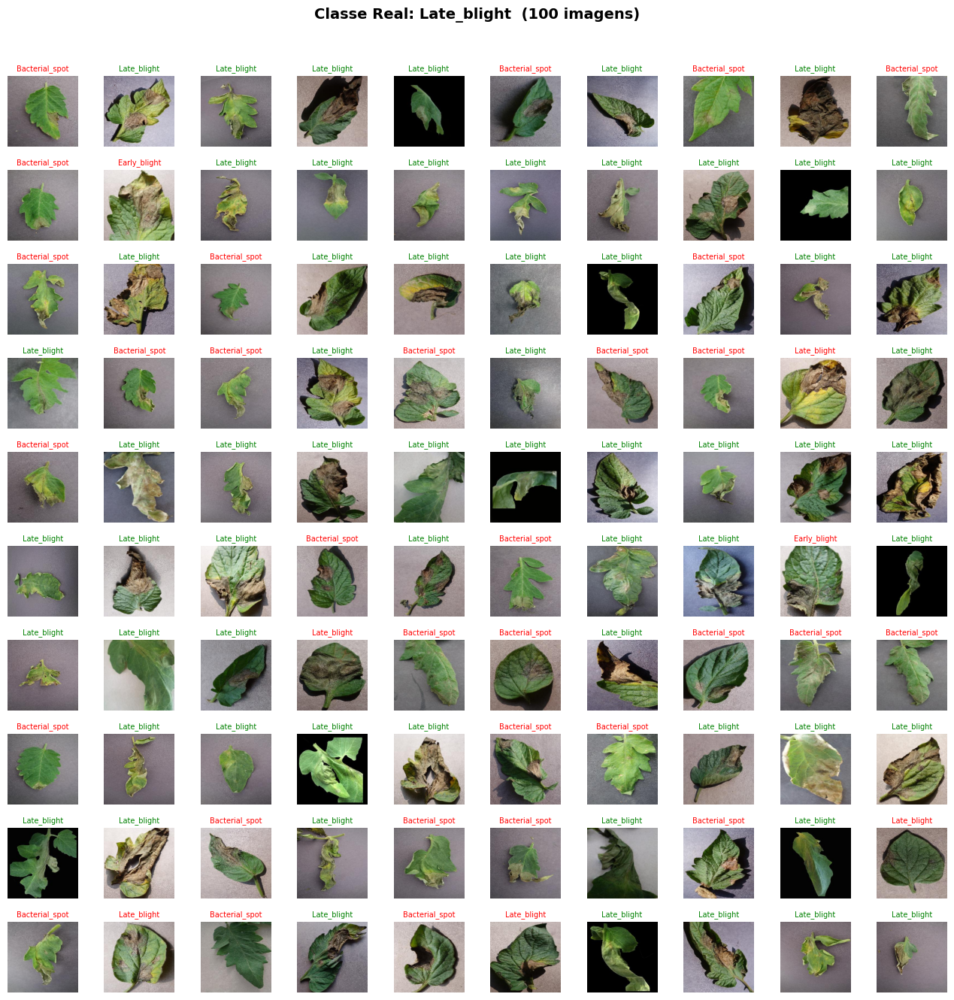

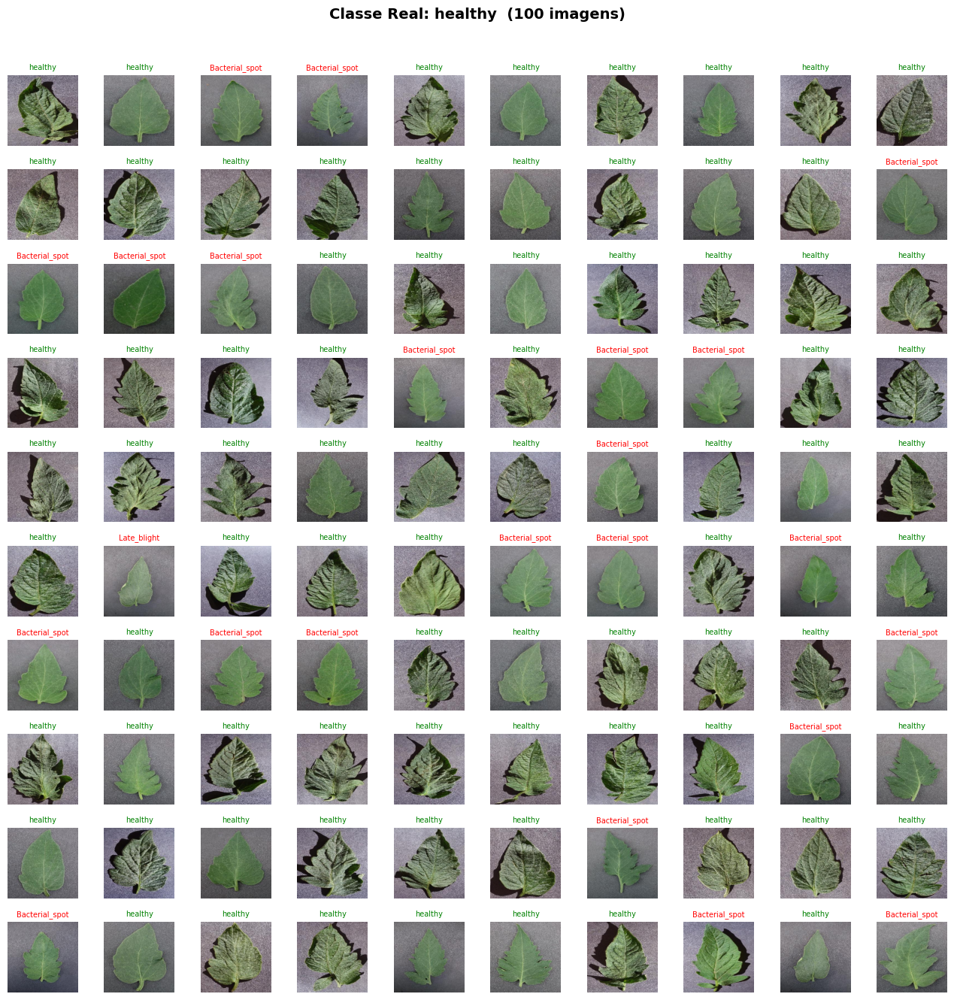

In [7]:
import math

for classe_id, nome_classe_completo in enumerate(query_dataset.classes):
    amostras_da_classe = [(query_dataset.samples[i][0], y_true[i], y_pred[i])
                           for i in range(len(y_true)) if y_true[i] == classe_id]
    n = len(amostras_da_classe)
    cols = 10
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.3, rows * 1.3))
    fig.suptitle(f"Classe Real: {nome_classe_completo.split('___')[-1]}  ({n} imagens)",
                 fontsize=14, weight='bold', y=1.02)

    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < n:
            img_path, classe_real, pred = amostras_da_classe[i]
            nome_predito = query_dataset.classes[pred].split("___")[-1]
            cor = 'green' if pred == classe_real else 'red'
            ax.imshow(Image.open(img_path))
            ax.set_title(nome_predito, fontsize=7, color=cor)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_edgecolor(cor)
                spine.set_linewidth(2)

    plt.tight_layout()
    plt.show()